# Recovery of annotated brain-specific cassette exons

VastDB calls a brain-specific cassette exon in a gene. `analysis/found_CE.tsv` records whether Torino recovered the isoform that **includes** the exon (`found_exon`), the isoform that **skips** it (`found_skip`), both, or neither.

This asks what separates the events we recover from the ones we miss — a nicer replacement for `analysis/foundCE_expression.png`, with the statistics the four-way split cannot carry on its own.

**The answer:** expression *in brain*. Not overall abundance, not exon length, not tissue specificity, not constraint.

Numbers come from `prepare_sfig2_foundce.py`; this notebook only draws.

In [1]:
import os
import pickle

import numpy as np
import pandas as pd
import matplotlib as mpl
from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle

FIG_DIR  = '/project2/yangili1/cfbuenabadn/torino_paper/notebooks/SFigure2'
DATA_PKL = os.path.join(FIG_DIR, 'figure_data', 'sfig2_foundce.pkl')

mpl.rcParams.update({
    'pdf.fonttype':      42,
    'ps.fonttype':       42,
    # 'none' keeps text editable in Inkscape instead of outlining every glyph.
    'svg.fonttype':      'none',
    'font.family':       'sans-serif',
    'font.sans-serif':   ['DejaVu Sans'],
    'axes.linewidth':    0.5,
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'xtick.major.size':  1.6,
    'ytick.major.size':  1.6,
    'savefig.dpi':       400,
})

## Page plan

Millimetres from a top-left origin, same method as the Figure 3 supplements. `PAGE['h']` is derived from the vertical plan, so a changed gutter propagates rather than silently pushing a label off the sheet.

In [2]:
PAGE_W   = 180.0
MARGIN_L = 2.0
MARGIN_R = 2.0
MARGIN_T = 1.0
MARGIN_B = 2.0
CONTENT_W = PAGE_W - MARGIN_L - MARGIN_R

TITLE_H  = 9.5        # title + two subtitle lines
SUB_LINE = 2.3
LETTER_H = 6.5
ROW_GAP  = 4.0
COL_GAP  = 9.0
GUTTER_L = 12.0       # y label + tick labels
ROW_FOOT = 9.5        # rotated x ticks + x label

FS_PANEL = 8.0
FS_TITLE = 7.0
FS_SUB   = 6.0
FS_TICK  = 5.0
FS_LABEL = 5.5
FS_ANNOT = 5.0
FS_SMALL = 4.6

TITLE_PAD   = 2.0
TITLE_PAD_N = 7.5     # where a row of group sizes sits above the axes

PAGE = {'h': 120.0}


def rect(x, y, w, h):
    return [x / PAGE_W, 1.0 - (y + h) / PAGE['h'], w / PAGE_W, h / PAGE['h']]


def add_ax(fig, x, y, w, h, **kw):
    ax = fig.add_axes(rect(x, y, w, h), **kw)
    ax.tick_params(labelsize=FS_TICK, pad=1.2)
    ax.spines[['top', 'right']].set_visible(False)
    return ax


def panel_letter(fig, letter, x, y):
    fig.text(x / PAGE_W, 1.0 - y / PAGE['h'], letter,
             fontsize=FS_PANEL, fontweight='bold', va='top', ha='left')


def fig_text(fig, x, y, s, **kw):
    return fig.text(x / PAGE_W, 1.0 - y / PAGE['h'], s, **kw)

## Palette

Colour encodes the outcome that matters — was the exon-containing isoform recovered? — while the x order stays the one the original plot used. Blue = inclusion isoform found, tan = missed, grey = neither isoform found.

In [3]:
# Colour encodes the outcome that matters — was the exon-containing isoform
# recovered? — while the x order stays the one the original plot used.
CAT_COLORS = {
    'CE & flanking': '#2B5D8C',     # both isoforms recovered
    'flanking only': '#C6A15B',     # exon-containing isoform missed
    'CE only':       '#6FA8D6',     # exon recovered, skipping isoform missed
    'None':          '#CFCFCF',     # neither
}
CAT_SHORT = {
    'CE & flanking': 'Both',
    'flanking only': 'Skipping\nonly',
    'CE only':       'Inclusion\nonly',
    'None':          'Neither',
}

VALUE_LABEL = {
    'log2_brain_tpm':       'Brain expression',
    'log2_median_tpm_cons': 'Overall expression',
    'log2_exon_len':        'Exon length',
    'tau_cons':             'Tissue specificity (τ)',
    'pLI':                  'pLI',
    'loeuf':                'LOEUF',
}
# Order for the effect panel: the two that matter, then the three that do not.
EFFECT_ORDER = ['log2_brain_tpm', 'pLI', 'log2_median_tpm_cons',
                'loeuf', 'log2_exon_len', 'tau_cons']

TERM_LABEL = {
    'log2_brain_tpm':       'Brain expression',
    'log2_median_tpm_cons': 'Overall expression',
    'log2_exon_len':        'Exon length',
    'tau_cons':             'Tissue specificity',
    'loeuf':                'LOEUF',
}

_SUPS = {'-': '⁻', '0': '⁰', '1': '¹', '2': '²', '3': '³', '4': '⁴',
         '5': '⁵', '6': '⁶', '7': '⁷', '8': '⁸', '9': '⁹'}


def _sup(n):
    """Unicode superscripts — mathtext would make the label uneditable."""
    return ''.join(_SUPS[c] for c in str(n))


def p_text(p):
    if not np.isfinite(p):
        return 'n/a'
    if p >= 0.001:
        return f'P = {p:.3f}'
    exp = int(np.floor(np.log10(p)))
    return f'P = {p / 10 ** exp:.1f}×10{_sup(exp)}'

## Data

`figure_data/sfig2_foundce.pkl`. Expression and constraint are **reused** from the Figure 3 supplement's prep (`prepare_sfig3_expression.py`), not re-derived, so the two supplements cannot disagree about what "median TPM" means.

- **Overall expression** — GTEx v8 median TPM across the five tissues the SSMD conservation call uses.
- **Brain expression** — the larger of the Brain and Cerebellum tissue groups.
- **Exon length** — from the `exon` coordinate in `found_CE.tsv`.
- **Constraint** — gnomAD v4.1.2 pLI and LOEUF, MANE Select transcript.

In [4]:
def load_data(path=DATA_PKL):
    with open(path, 'rb') as fh:
        return pickle.load(fh)

## Panel a — what was recovered

167 events: 90 both, 62 skipping only, 7 inclusion only, 8 neither. The marginals are what the rest of the figure is about — the inclusion isoform is recovered 58% of the time, the skipping isoform 91%.

In [5]:
def draw_counts(ax, res):
    """The four outcomes, with the two marginal recovery rates spelled out."""
    cats = res['categories']
    counts = res['counts'].reindex(cats).values.astype(float)
    xs = np.arange(len(cats))

    ax.bar(xs, counts, width=0.68, color=[CAT_COLORS[c] for c in cats],
           edgecolor='black', lw=0.4)
    for x, n in zip(xs, counts):
        ax.text(x, n + 1.5, f'{int(n)}', ha='center', va='bottom',
                fontsize=FS_SMALL, color='0.25')

    ax.set_xticks(xs)
    ax.set_xticklabels([CAT_SHORT[c] for c in cats], fontsize=FS_TICK)
    ax.set_ylabel('VastDB cassette exons', fontsize=FS_LABEL, labelpad=1.5)
    ax.set_xlabel('Torino isoforms recovered', fontsize=FS_LABEL, labelpad=1.5)
    ax.set_ylim(0, counts.max() * 1.42)

    n = res['n_events']
    ax.text(0.5, 0.98,
            f'Inclusion isoform: {res["n_found_exon"]}/{n} '
            f'({100 * res["n_found_exon"] / n:.0f}%)\n'
            f'Skipping isoform:  {res["n_found_skip"]}/{n} '
            f'({100 * res["n_found_skip"] / n:.0f}%)',
            transform=ax.transAxes, ha='center', va='top',
            fontsize=FS_ANNOT, linespacing=1.4)
    return ax

## Panels b and c — distributions by outcome

Box widths follow √n: two of the four cells hold 7 and 8 events and should not read as equal evidence to the other two. For the same reason each panel prints both the four-way Kruskal–Wallis and the binary test (inclusion isoform found vs not), which is where the statistics actually rest.

In [6]:
def draw_by_category(ax, res, value, ylabel, log2_ticks=False):
    """
    Box-and-whisker per outcome.  Widths follow sqrt(n): two of the four cells
    hold 7 and 8 events and should not read as equal evidence to the other two.
    """
    cats = res['categories']
    st = res['by_category'][value]
    groups = [st['groups'][c] for c in cats]
    ns = np.array([len(g) for g in groups], dtype=float)
    widths = 0.28 + 0.40 * np.sqrt(ns / ns.max())

    bp = ax.boxplot(groups, positions=np.arange(len(cats)), widths=widths,
                    patch_artist=True, showfliers=False, whis=(10, 90),
                    medianprops=dict(color='black', lw=0.8),
                    boxprops=dict(lw=0.4), whiskerprops=dict(lw=0.4),
                    capprops=dict(lw=0.4))
    for patch, c in zip(bp['boxes'], cats):
        patch.set_facecolor(CAT_COLORS[c])
        patch.set_edgecolor('black')

    ax.set_xticks(np.arange(len(cats)))
    ax.set_xticklabels([CAT_SHORT[c] for c in cats], fontsize=FS_TICK)
    ax.set_ylabel(ylabel, fontsize=FS_LABEL, labelpad=1.5)
    ax.set_xlabel('Torino isoforms recovered', fontsize=FS_LABEL, labelpad=1.5)

    y0, y1 = ax.get_ylim()
    ax.set_ylim(y0, y1 + 0.22 * (y1 - y0))

    trans = mpl.transforms.blended_transform_factory(ax.transData, ax.transAxes)
    for i, n in enumerate(ns):
        ax.text(i, 1.01, f'{int(n)}', transform=trans, ha='center', va='bottom',
                fontsize=FS_SMALL, color='0.25')

    # The four-way Kruskal-Wallis and the binary test the statistics rest on
    out = res['by_outcome'][value]
    ax.text(0.02, 0.98,
            f'4 groups:  {p_text(st["kw_p"])}\n'
            f'inclusion found vs not:  {p_text(out["p"])}',
            transform=ax.transAxes, ha='left', va='top',
            fontsize=FS_ANNOT, linespacing=1.4)

    if log2_ticks:
        ax.yaxis.set_major_locator(mpl.ticker.MultipleLocator(2))
    return ax

## Panel d — effect sizes

Rank-biserial correlation between each variable and recovery of the exon-containing isoform. Six variables on six different scales are only comparable once reduced to a common effect size. Grey = P ≥ 0.05.

In [7]:
def draw_effects(ax, res):
    """
    Rank-biserial correlation between each variable and whether the
    exon-containing isoform was recovered.  Six variables on six scales are
    only comparable once reduced to a common effect size.
    """
    ys = np.arange(len(EFFECT_ORDER))[::-1]
    ax.axvline(0, color='0.6', lw=0.5, zorder=1)

    for v, y in zip(EFFECT_ORDER, ys):
        s = res['by_outcome'][v]
        sig = s['p'] < 0.05
        c = '#2B5D8C' if sig else '0.55'
        ax.plot([s['rb_lo'], s['rb_hi']], [y, y], color=c, lw=0.7,
                solid_capstyle='butt', zorder=2)
        ax.plot(s['rank_biserial'], y, marker='o', ms=3.0, color=c,
                mec='white', mew=0.3, zorder=3)
        ax.text(0.99, y, p_text(s['p']), transform=ax.get_yaxis_transform(),
                ha='right', va='center', fontsize=FS_SMALL,
                color=('0.2' if sig else '0.55'))

    ax.set_yticks(ys)
    ax.set_yticklabels([VALUE_LABEL[v] for v in EFFECT_ORDER], fontsize=FS_TICK)
    ax.set_ylim(ys[-1] - 0.6, ys[0] + 0.6)
    ax.set_xlabel('Rank-biserial correlation with recovery of the\n'
                  'exon-containing isoform  (95% bootstrap CI)',
                  fontsize=FS_LABEL, labelpad=1.5)
    ax.tick_params(axis='y', length=0)

    lo, hi = ax.get_xlim()
    ax.set_xlim(lo, hi + 0.42 * (hi - lo))      # room for the P column
    return ax

## Panel e — recovery rate against brain expression

Recovery rate across brain-expression quartiles with binomial CIs, and the logistic model built on brain expression rather than the five-tissue median — a brain-specific exon needs brain coverage to be seen, so that is the covariate the biology predicts.

In [8]:
def draw_rate(ax, res):
    """Recovery rate across brain-expression quartiles, with binomial CIs."""
    r = res['rate_brain']
    xs = r['centre'].values

    ax.fill_between(xs, 100 * r['lo'].values, 100 * r['hi'].values,
                    color='#2B5D8C', alpha=0.16, lw=0)
    ax.plot(xs, 100 * r['rate'].values, color='#2B5D8C', lw=0.9, marker='o',
            ms=2.8, mec='white', mew=0.3, zorder=3)

    base = 100 * res['n_found_exon'] / res['n_events']
    ax.axhline(base, color='0.5', lw=0.5, ls='--', zorder=1)
    # At the left end the baseline label clears both the curve and its ribbon;
    # at the right it sat on top of the last point.
    ax.text(xs[0], base + 1.5, f'overall {base:.0f}%', ha='left', va='bottom',
            fontsize=FS_SMALL, color='0.4')

    ax.set_xlabel('Brain expression (log₂ TPM, quartile medians)',
                  fontsize=FS_LABEL, labelpad=1.5)
    ax.set_ylabel('Exon-containing isoform\nrecovered (%)',
                  fontsize=FS_LABEL, labelpad=1.5)
    # Headroom for the model block, with the axis still read as 0-100 %.
    ax.set_ylim(0, 142)
    ax.set_yticks([0, 20, 40, 60, 80, 100])

    m = res['model']
    lines = [f'{TERM_LABEL[t]}:  OR = {np.exp(m["params"][t]):.2f}, '
             f'{p_text(m["pvalues"][t])}' for t in m['terms']]
    ax.text(0.02, 0.98,
            'Logistic model, per s.d.\n' + '\n'.join(lines),
            transform=ax.transAxes, ha='left', va='top',
            fontsize=FS_ANNOT, linespacing=1.4)
    return ax

## Assembling the figure

In [9]:
PANEL_H = 33.0

# Row 1: three panels.  Row 2: two wider ones.
R1_W = (CONTENT_W - 3 * GUTTER_L - 2 * COL_GAP) / 3
R1_X = [MARGIN_L + GUTTER_L + i * (R1_W + COL_GAP + GUTTER_L) for i in range(3)]

R2_GUTTER = 26.0                       # panel d's variable names are long
R2_W = (CONTENT_W - 2 * R2_GUTTER - COL_GAP) / 2
R2_X = [MARGIN_L + R2_GUTTER, MARGIN_L + R2_GUTTER + R2_W + COL_GAP + R2_GUTTER]

ROW1_Y = MARGIN_T + TITLE_H + LETTER_H
ROW2_Y = ROW1_Y + PANEL_H + ROW_FOOT + ROW_GAP + LETTER_H
PAGE_H = ROW2_Y + PANEL_H + ROW_FOOT + MARGIN_B + 2.0


def build_figure(data=None):
    res = data if data is not None else load_data()
    PAGE['h'] = PAGE_H
    fig = plt.figure(figsize=(PAGE_W / 25.4, PAGE_H / 25.4))

    n = res['n_events']
    fig_text(fig, PAGE_W / 2, MARGIN_T,
             'Recovery of annotated brain-specific cassette exons tracks '
             'expression in brain, not overall abundance',
             ha='center', va='top', fontsize=FS_TITLE)
    for i, line in enumerate([
            f'{n} VastDB brain-specific cassette exons in '
            f'{res["table"].gene.nunique()} genes.  For each, whether Torino '
            f'recovered the isoform including the exon, the isoform skipping '
            f'it, both or neither.',

            'Expression: GTEx v8 median TPM over the tissue groups the SSMD '
            'analysis uses.  Constraint: gnomAD v4.1.2.  Numbers above the '
            'boxes are event counts.']):
        fig_text(fig, PAGE_W / 2, MARGIN_T + 3.2 + i * SUB_LINE, line,
                 ha='center', va='top', fontsize=FS_ANNOT, color='0.3')

    # --- row 1 ---
    panel_letter(fig, 'a', R1_X[0] - GUTTER_L, ROW1_Y - LETTER_H)
    ax = add_ax(fig, R1_X[0], ROW1_Y, R1_W, PANEL_H)
    draw_counts(ax, res)
    ax.set_title('Most exons are recovered on at least one isoform',
                 fontsize=FS_SUB, pad=TITLE_PAD)

    panel_letter(fig, 'b', R1_X[1] - GUTTER_L, ROW1_Y - LETTER_H)
    ax = add_ax(fig, R1_X[1], ROW1_Y, R1_W, PANEL_H)
    draw_by_category(ax, res, 'log2_median_tpm_cons',
                     'Overall expression\n(log₂ median TPM)', log2_ticks=True)
    ax.set_title('Overall expression separates them weakly',
                 fontsize=FS_SUB, pad=TITLE_PAD_N)

    panel_letter(fig, 'c', R1_X[2] - GUTTER_L, ROW1_Y - LETTER_H)
    ax = add_ax(fig, R1_X[2], ROW1_Y, R1_W, PANEL_H)
    draw_by_category(ax, res, 'log2_brain_tpm',
                     'Brain expression\n(log₂ TPM)', log2_ticks=True)
    ax.set_title('Brain expression separates them clearly',
                 fontsize=FS_SUB, pad=TITLE_PAD_N)

    # --- row 2 ---
    panel_letter(fig, 'd', MARGIN_L, ROW2_Y - LETTER_H)
    ax = add_ax(fig, R2_X[0], ROW2_Y, R2_W, PANEL_H)
    draw_effects(ax, res)
    ax.set_title('What predicts recovery, and what does not',
                 fontsize=FS_SUB, pad=TITLE_PAD)

    panel_letter(fig, 'e', R2_X[1] - R2_GUTTER, ROW2_Y - LETTER_H)
    ax = add_ax(fig, R2_X[1], ROW2_Y, R2_W, PANEL_H)
    draw_rate(ax, res)
    ax.set_title('Recovery rises with brain expression',
                 fontsize=FS_SUB, pad=TITLE_PAD)

    return fig

## Render

Written as `.png`, `.pdf` and `.svg`; the SVG keeps text as editable `<text>` elements.

SFigure2_foundCE  180 x 116.5 mm  -> SFigure2_foundCE.png/.pdf/.svg


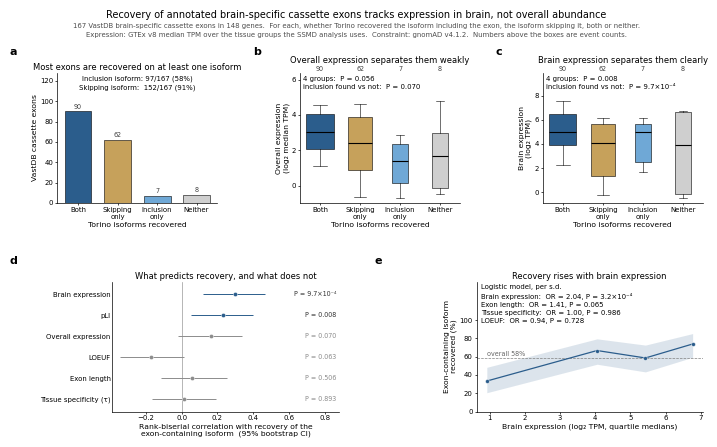

In [10]:
data = load_data()
fig = build_figure(data)

STEM = 'SFigure2_foundCE'
for _ext, _kw in (('png', dict(dpi=400)), ('pdf', {}), ('svg', {})):
    fig.savefig(os.path.join(FIG_DIR, f'{STEM}.{_ext}'), facecolor='white', **_kw)
print(f'{STEM}  {PAGE_W:.0f} x {PAGE_H:.1f} mm  -> {STEM}.png/.pdf/.svg')

## Numbers quoted in the figure

In [11]:
print(f'{data["n_events"]} events in {data["table"].gene.nunique()} genes')
print(data['counts'].to_string())
print(f'\ninclusion isoform recovered: {data["n_found_exon"]}/{data["n_events"]}'
      f'   skipping isoform: {data["n_found_skip"]}/{data["n_events"]}\n')

print('recovered vs missed (inclusion isoform):')
for v in EFFECT_ORDER:
    s = data['by_outcome'][v]
    print(f'  {VALUE_LABEL[v]:24s} found {s["median_found"]:8.3f} '
          f'(n={s["n_found"]})   missed {s["median_missed"]:8.3f} '
          f'(n={s["n_missed"]})   r = {s["rank_biserial"]:+.3f} '
          f'[{s["rb_lo"]:+.3f}, {s["rb_hi"]:+.3f}]   {p_text(s["p"])}')

for key, label in (('model', 'brain expression'),
                   ('model_overall', 'overall expression'),
                   ('model_both', 'both expression terms')):
    m = data[key]
    print(f'\nlogistic model — {label} (n={m["n"]}, '
          f'pseudo-R² = {m["prsquared"]:.4f}):')
    for t in m['terms']:
        print(f'  {TERM_LABEL[t]:22s} OR = {np.exp(m["params"][t]):.3f} '
              f'[{np.exp(m["ci_lo"][t]):.3f}, {np.exp(m["ci_hi"][t]):.3f}]   '
              f'{p_text(m["pvalues"][t])}')

print('\nrecovery rate by brain-expression quartile:')
print(data['rate_brain'].to_string(float_format=lambda x: f'{x:7.3f}'))

167 events in 148 genes
category
CE & flanking    90
flanking only    62
CE only           7
None              8

inclusion isoform recovered: 97/167   skipping isoform: 152/167

recovered vs missed (inclusion isoform):
  Brain expression         found    5.016 (n=97)   missed    4.035 (n=70)   r = +0.300 [+0.120, +0.463]   P = 9.7×10⁻⁴
  pLI                      found    0.983 (n=96)   missed    0.014 (n=70)   r = +0.232 [+0.055, +0.396]   P = 0.008
  Overall expression       found    2.920 (n=97)   missed    2.327 (n=70)   r = +0.165 [-0.020, +0.340]   P = 0.070
  LOEUF                    found    0.482 (n=96)   missed    0.549 (n=70)   r = -0.169 [-0.346, +0.014]   P = 0.063
  Exon length              found    5.728 (n=97)   missed    5.491 (n=70)   r = +0.061 [-0.114, +0.251]   P = 0.506
  Tissue specificity (τ)   found    0.769 (n=97)   missed    0.761 (n=70)   r = +0.012 [-0.166, +0.193]   P = 0.893

logistic model — brain expression (n=166, pseudo-R² = 0.0862):
  Brain expressio